# Самостоятельный проект: очередь проверки рукописных цифр

## 1. Цель
Проверить, сколько ошибок отдельных цифр оставляет автоматизация после очереди из 37 цифр. Выбираю модель по validation, правило confidence фиксирую до меток финальной партии. Критерий: качество цифр выше простого ориентира и измеренное число пропущенных ошибок. Прогноз целых телефонов из этих данных не оценивается.

In [1]:
import sys,json,time,joblib
from pathlib import Path
import numpy as np,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score,confusion_matrix
from scipy.ndimage import gaussian_filter
RANDOM_STATE=42
VALIDATION_RANDOM_STATE=7
ART=Path('digits_transfer');ART.mkdir(exist_ok=True)
print('Python',sys.version.split()[0],'numpy',np.__version__,'sklearn',sklearn.__version__)


Python 3.12.14 numpy 2.4.6 sklearn 1.8.0


**Вывод по цели.** Единица автоматизации — отдельная цифра. Проверка 37 цифр из 450 будет нагрузкой 8.22% по символам; число карточек и экономия времени по этим данным неизвестны. Импорты и версии среды показаны выше, критерий качества модели определён до обучения.

## 2. Данные
Sklearn digits: одна строка — отдельный символ 8×8,64 яркости 0..16,1797 строк. Это учебный набор; нет связи с анкетой, номера телефона и результатов оператора.

(1797, 64) missing 0 range 0.0 1.0
counts [178 182 177 183 181 182 181 179 174 180]


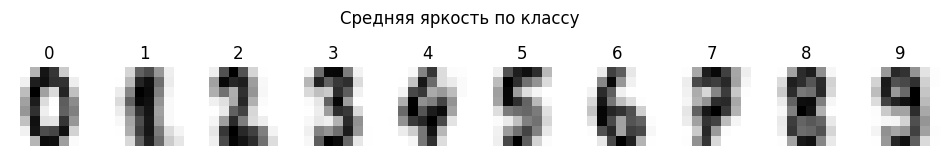

In [2]:
digits=load_digits();X=digits.data/16.;y=digits.target
print(X.shape,'missing',np.isnan(X).sum(),'range',X.min(),X.max())
print('counts',np.bincount(y))
fig,axes=plt.subplots(1,10,figsize=(12,2))
for k,ax in enumerate(axes):
    ax.imshow(digits.images[y==k].mean(axis=0),cmap='gray_r');ax.set_title(str(k));ax.axis('off')
fig.suptitle('Средняя яркость по классу');plt.show()


**Вывод по данным.**1797 символов и 64 признака, классы имеют около 180 примеров. Средние формы подходят для первичного осмотра, но индивидуальный почерк и шум на сканах здесь не представлены.

## 3. Предобработка
Делю яркость на 16 по известной шкале; статистики теста не нужны. Финальные 25% откладываю до выбора модели и правила; в development ещё 25%validation. Дубли автоматически не удаляю: одинаковая картинка может быть отдельным наблюдением; явно отчитаюсь об их числе.

In [3]:
print('duplicate pixel rows',len(X)-len(np.unique(X,axis=0)))
ix=np.arange(len(y));dev_idx,final_idx=train_test_split(ix,test_size=.25,random_state=RANDOM_STATE,stratify=y)
fit_idx,val_idx=train_test_split(dev_idx,test_size=.25,random_state=VALIDATION_RANDOM_STATE,stratify=y[dev_idx])
print('fit,val,final',len(fit_idx),len(val_idx),len(final_idx))


duplicate pixel rows 0
fit,val,final 1010 337 450


**Вывод по предобработке.**Обучение 1010,валидация 337,финал 450. Общая подготовка — заданная шкала 0..1; финальные метки до фиксации выбора не участвуют в сравнении.

## 4. Анализ и модели
Сравниваю Dummy,логит,kNN3,MLP64. Основная метрикаaccuracy на validation. Затем фиксирую выбранный рецепт и ruleconfidence с tie-break по позиции. Дополнительно проверяю новое размытие; правило очереди тоже сохраняется до доступа к финальным меткам.

In [4]:
recipes={'dummy':lambda:DummyClassifier(strategy='most_frequent'),'logit':lambda:LogisticRegression(max_iter=2000),'knn3':lambda:KNeighborsClassifier(n_neighbors=3),'mlp64':lambda:MLPClassifier(hidden_layer_sizes=(64,),alpha=.001,max_iter=500,random_state=RANDOM_STATE)}
rows=[]
for name,recipe in recipes.items():
    candidate=recipe().fit(X[fit_idx],y[fit_idx]);rows.append({'model':name,'validation_accuracy':candidate.score(X[val_idx],y[val_idx])})
log=pd.DataFrame(rows);best_name=str(log.sort_values(['validation_accuracy','model'],ascending=[False,True]).iloc[0]['model'])
print(log.to_string(index=False));print('frozen model',best_name)
selected=recipes[best_name]().fit(X[dev_idx],y[dev_idx])
def blur(batch):
    return np.array([gaussian_filter(im.reshape(8,8),sigma=.65,mode='constant',cval=0) for im in batch]).reshape(-1,64)
request=X[final_idx];blurred=blur(request);P=selected.predict_proba(blurred);pred=selected.classes_[P.argmax(axis=1)];confidence=P.max(axis=1)
queue=np.lexsort((np.arange(len(request)),confidence))[:37].tolist()
manifest={'model':best_name,'rule':'confidence','tie_break':'smaller_position','capacity_digits':37,'queue':queue,'unit':'digit','sigma':.65,'border':'constant0','reason':'Низкая максимальная вероятность даёт понятное правило без доступа к меткам. Уверенные ошибки этим правилом не гарантируется поймать.'}
(ART/'decision_before_labels.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
joblib.dump(selected,ART/'digits_model.joblib');np.save(ART/'control_features.npy',request[:16]);np.save(ART/'control_proba.npy',selected.predict_proba(request[:16]))
print('SAVED before opening final labels',manifest)


model  validation_accuracy
dummy             0.100890
logit             0.964392
 knn3             0.988131
mlp64             0.970326
frozen model knn3
SAVED before opening final labels {'model': 'knn3', 'rule': 'confidence', 'tie_break': 'smaller_position', 'capacity_digits': 37, 'queue': [239, 32, 42, 43, 44, 45, 90, 95, 112, 115, 116, 131, 144, 146, 166, 181, 185, 191, 199, 200, 226, 230, 240, 241, 276, 283, 286, 301, 321, 329, 342, 346, 356, 366, 370, 372, 397], 'unit': 'digit', 'sigma': 0.65, 'border': 'constant0', 'reason': 'Низкая максимальная вероятность даёт понятное правило без доступа к меткам. Уверенные ошибки этим правилом не гарантируется поймать.'}


{'model': 'knn3', 'clean_accuracy': 0.9844444444444445, 'blur_accuracy': 0.9488888888888889, 'total_errors': 23, 'caught_errors': 12, 'missed_errors': 11, 'review_share': 0.08222222222222222, 'phone_accuracy': None}


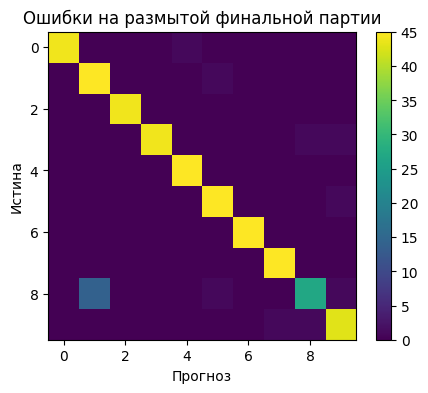

Restored model:16control predictions match


In [5]:
# Открываю final labels только после записанногоmanifest.
final_labels=y[final_idx];wrong=pred!=final_labels;inside=np.zeros(len(wrong),dtype=bool);inside[queue]=True
clean_acc=selected.score(request,final_labels);blur_acc=accuracy_score(final_labels,pred)
metrics={'model':best_name,'clean_accuracy':float(clean_acc),'blur_accuracy':float(blur_acc),'total_errors':int(wrong.sum()),'caught_errors':int((wrong&inside).sum()),'missed_errors':int((wrong&~inside).sum()),'review_share':len(queue)/len(request),'phone_accuracy':None}
print(metrics)
pd.DataFrame({'position':np.arange(len(request)),'original_index':final_idx,'truth':final_labels,'prediction':pred,'confidence':confidence,'review':inside}).to_csv(ART/'evaluation.csv',index=False)
(ART/'metrics.json').write_text(json.dumps(metrics,indent=2));log.to_csv(ART/'validation.csv',index=False)
cm=confusion_matrix(final_labels,pred)
fig,ax=plt.subplots(figsize=(5,4));im=ax.imshow(cm);ax.set_xlabel('Прогноз');ax.set_ylabel('Истина');ax.set_title('Ошибки на размытой финальной партии');plt.colorbar(im,ax=ax);plt.show()
restored=joblib.load(ART/'digits_model.joblib');np.testing.assert_allclose(restored.predict_proba(np.load(ART/'control_features.npy')),np.load(ART/'control_proba.npy'))
print('Restored model:16control predictions match')


**Вывод по анализу.** На validation kNN3 дал .98813 против .97033 у MLP64 и .10089 у Dummy. После фиксации kNN и очереди 37 цифр итоговая accuracy чистых картинок .98444, размытых .94889. Из 23 ошибок очередь поймала 12, вне неё осталось 11; нагрузка 37/450=.08222. Это цифры, не полные анкеты. Сохранённая модель воспроизвела 16 контрольных вероятностей.

## 5. Выводы и рекомендации
Самостоятельный результат передаётся как модель,контрольныепрогнозы,решение до меток,таблица ошибок. Не предлагаю записывать телефоны автоматически: нужны реальные анкеты, сегментация, связьцифр сзаписью ипорядок,эталонполнойстрокой(включая начальные нули),результат оператора и нагрузка по карточкам. Для восьмизначного кода считаю среднее точного совпадения всех 8 символов, без предположения независимости. Качество цифр наdigits не доказывает экономию времени оператора.